# Musical genre replication — Harsha and Sunil

## Phase 0 — Project overview and references

We learn genre information directly from audio amplitudes. A **waveform** records air-pressure-related amplitude over time. An **embedding** is a shorter vector learned from that waveform. An **autoencoder** compresses input into an embedding and reconstructs the input. **Joint training** also asks the embedding to predict genre, using both reconstruction error and classification error.

This notebook contains all project logic. Run cells in order in VS Code, one numbered phase at a time. Default `mode="smoke"` exercises the complete workflow briefly on real audio; it **does not reproduce the full experiments**. Full training is an explicit configuration change. Checkpoints, arrays, figures and metadata are stored outside the notebook. No project-specific Python module is imported.

Primary references (read in full): [paper](references/musical_genre.pdf), [poster](references/musical_genre_poster.pdf), and [assignment guidelines](references/Guidelines%20and%20Instructions_Mini%20Project%20Assignment.pdf). The [author repository, pinned revision](https://github.com/arjunsawknee/Genre-Extraction/tree/00b1802e24d1ab6fb3135b24a44976a51033ed24) supplies supplemental evidence; this revision is not proof of the exact published run.

| Decision | Evidence and interpretation |
|---|---|
| Genres and waveform input | Paper §§2–3, pp.1–2: classical, jazz, metal, pop; raw amplitudes, no MFCCs/mel features. Poster explicitly says 400 recordings. |
| 8,000 × 500 inputs | Paper §3, p.2 says one-second clips, 22.05 kHz, 20,000 values and pooling by 40: inconsistent literally. [Author loader lines 28–69](https://github.com/arjunsawknee/Genre-Extraction/blob/00b1802e24d1ab6fb3135b24a44976a51033ed24/softmaxautoencoder.py#L28-L69) uses twenty consecutive chunks of 500 pooled samples, corresponding to the first 400,000 raw samples. Harsha approved this interpretation: twenty **20,000-sample / 0.907029-second** chunks per recording. |
| Truncation detail | Author code first pools 600,000 samples but uses only the first 400,000. We process the contributing 400,000 directly; for sufficiently long native audio this produces the same used values. No resampling, padding, gain normalization or random segment selection. |
| Split | Paper §3/Table 1, pp.2–3: random 6,000/1,000/1,000 examples. Poster/source use 6,000/2,000; source AE trains on all 8,000. We follow paper sizes and train every model only on the training split. Seed is a new documented choice; original membership cannot be recovered. |
| Models | Paper §4/Fig.2, pp.2–3: 500→128 tanh→4 classifier; encoder 500→256→192→128→64 and reversed decoder; joint head 64→32→16→4. |
| Optimization | Fig.2: Adam, 1e-4, batch 512. Paper §5.1 p.4: keep probability .9, hence dropout .1. Apply optimizer settings to all models, supported by source. |
| Source-only activations/defaults | Encoder sigmoid/tanh/ReLU/ReLU; decoder sigmoid/sigmoid/ReLU/ReLU; joint head tanh/tanh/linear. Dropout follows the encoder/decoder 192-unit activation. Xavier weights/zero biases. Baseline has no dropout in source. Preserve these settings here; decoder ReLU cannot reconstruct negative amplitude, a limitation. |
| Loss precedence | Paper Eqs.2–3: squared L2 per example, jointly weighted .9 reconstruction/.1 CE. Source uses elementwise mean MSE + .1 CE, changing relative weighting by 450×. We implement paper equations: **sum input dimensions, then mean examples**. |
| Duration and selection | Source baseline/joint 200 epochs, AE 400; paper Fig.3 reaches about 500 and lacks a complete stopping rule. Use source budgets, explicitly as an assumption; select minimum validation objective within that budget. Smoke uses one epoch of a small training subset and is never labeled a full result. |
| Framework / other choices | PyTorch replaces source TensorFlow. Float32, deterministic CPU default, fixed seed, per-epoch shuffling, sample-weighted reporting, fixed Adam defaults and validation checkpoint selection are recorded implementation choices. |

Paper comparison accuracy (not our results): baseline train/dev/test **52.0/38.1/36.4%**; joint **94.9/64.1/65.3%** (Table 1, p.3). The AE has no classifier; do not invent its genre accuracy. Paper Fig.4's title says validation but caption says test. Our figures identify their actual partition.

Assignment: private GitHub repo shared with faculty/TAs, reproducible README, PDF covering problem/data/approach/implementation/conclusions, slides, live demo and both members' Q&A. Reviews **October 5–9, 2026**; submission **October 10, 2026 at 11:59 PM** (timezone not stated). The “One-Page” heading contradicts “two-page” body text; faculty clarification remains necessary. This notebook does not replace the PDF, slides, access verification or live review. See `plan.md` for balanced responsibilities; automated assistance is not human contribution evidence.


## Phase 1 — Environment and dataset

In VS Code, open this notebook, choose **Select Kernel → Python Environments → `.venv/bin/python`** (Windows: `.venv\Scripts\python.exe`). Run the following in a terminal from the project directory to create a suitable environment. Python 3.12+ is required. The optional requirements file pins the verified environment, but no project-specific code file is required.

```bash
python3 -m venv .venv
.venv/bin/python -m pip install numpy soundfile torch scikit-learn matplotlib pandas ipykernel nbformat nbclient
# Alternatively install the recorded exact versions:
# .venv/bin/python -m pip install -r requirements-notebook.txt
```

The next cells import libraries and define **all configurable experiment choices in one cell**. Keep `mode="smoke"` for the first run. For the full experiments change it to `"full"`; training may take substantial time. Keep `evaluate_test=False` during development. Only enable it after choices are fixed. Saved matching checkpoints are loaded automatically; set `force_retrain=True` only intentionally.


In [1]:
from pathlib import Path, PurePosixPath
from collections import Counter
from datetime import datetime, timezone
import copy, hashlib, importlib.metadata, json, math, os, platform, random, sys, tarfile, time, urllib.request
import numpy as np
import pandas as pd
import soundfile as sf
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from IPython.display import Audio, display


In [2]:
# Change only this cell for an intentional experiment. Paths may be absolute.
CFG = {
    "project_root": str(Path.cwd()),
    "dataset_source": "qiuqiangkong",  # complete AU mirror; see provenance below
    "dataset_path": "data/raw/gtzan_qiuqiangkong",  # may point at existing audio
    "download_if_missing": True,
    "mode": "smoke",  # "smoke" or "full"
    "seed": 2026,
    "device": "cpu",  # cpu reproducibility default; optionally cuda or mps
    "torch_threads": 4,
    "sample_rate": 22050, "chunks_per_recording": 20,
    "chunk_samples": 20000, "pool_size": 40,
    "genres": ["classical", "jazz", "metal", "pop"],
    "split_sizes": [6000, 1000, 1000],
    "learning_rate": 0.0001, "batch_size": 512,
    "adam_betas": [0.9, 0.999], "adam_epsilon": 1e-8, "weight_decay": 0.0,
    "dropout_probability": 0.1, "gamma": 0.9,
    "encoder_activations": ["sigmoid", "tanh", "relu", "relu"],
    "decoder_activations": ["sigmoid", "sigmoid", "relu", "relu"],
    "head_activations": ["tanh", "tanh"],
    "initialization": "xavier_uniform_zero_bias", "dropout_after_width": 192,
    "full_epochs": {"baseline": 200, "autoencoder": 400, "joint": 200},
    "smoke_epochs": 1, "smoke_train_examples": 256, "smoke_val_examples": 128,
    "reuse_checkpoints": True, "force_retrain": False,
    "evaluate_test": False, "audio_playback": False,
    "implementation_version": "paper-l2-notebook-v1",
}
ROOT = Path(CFG["project_root"]).expanduser().resolve()
RAW = Path(CFG["dataset_path"]).expanduser()
RAW = RAW.resolve() if RAW.is_absolute() else (ROOT / RAW).resolve()
DOWNLOADS = ROOT / "data/downloads"
OUT = ROOT / "artifacts/notebook"
for folder in [DOWNLOADS, OUT]:
    if folder == RAW or RAW in folder.parents:
        raise ValueError("Generated files must be outside the raw-audio directory.")
    folder.mkdir(parents=True, exist_ok=True)
assert CFG["mode"] in {"smoke", "full"}
assert not (CFG["mode"] == "smoke" and CFG["evaluate_test"]), "Smoke runs must not inspect test."
assert CFG["sample_rate"] == 22050 and CFG["chunk_samples"] == 20000 and CFG["pool_size"] == 40
assert CFG["chunks_per_recording"] == 20 and CFG["split_sizes"] == [6000, 1000, 1000]
assert CFG["genres"] == ["classical", "jazz", "metal", "pop"]
assert CFG["initialization"] == "xavier_uniform_zero_bias" and CFG["dropout_after_width"] == 192
GENRES = CFG["genres"]
LABELS = {genre: i for i, genre in enumerate(GENRES)}
COLORS = {"classical": "#315da8", "jazz": "#21855b", "metal": "#cb791b", "pop": "#93509c"}
def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.use_deterministic_algorithms(True)
    if hasattr(torch.backends, "cudnn"):
        torch.backends.cudnn.benchmark = False
seed_everything(CFG["seed"])
torch.set_num_threads(CFG["torch_threads"])
DEVICE = torch.device(CFG["device"])
if DEVICE.type == "cuda" and not torch.cuda.is_available():
    raise RuntimeError("CUDA requested but unavailable; choose cpu in CFG.")
if DEVICE.type == "mps" and not torch.backends.mps.is_available():
    raise RuntimeError("MPS requested but unavailable; choose cpu in CFG.")
VERSIONS = {name: importlib.metadata.version(name) for name in
            ["numpy", "soundfile", "torch", "scikit-learn", "matplotlib", "pandas", "ipykernel"]}
VERSIONS.update(python=sys.version, platform=platform.platform(), libsndfile=sf.__libsndfile_version__)
def write_json(path, obj):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    Path(path).write_text(json.dumps(obj, indent=2, allow_nan=False) + "\n")
def fingerprint(obj):
    return hashlib.sha256(json.dumps(obj, sort_keys=True).encode()).hexdigest()
def file_hash(path):
    with Path(path).open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()
print("Mode:", CFG["mode"], "| device:", DEVICE, "| raw data:", RAW)
display(pd.Series(VERSIONS, name="version"))


Mode: smoke | device: cpu | raw data: /Users/harshak/Documents/GitHub/ML-Mini-Project/data/raw/gtzan_qiuqiangkong


numpy                                                       2.4.4
soundfile                                                  0.13.1
torch                                                      2.14.1
scikit-learn                                                1.9.1
matplotlib                                                 3.11.2
pandas                                                      3.0.6
ipykernel                                                   7.4.0
python          3.14.6 (main, Jun 10 2026, 10:03:53) [Clang 21...
platform                      macOS-26.6.2-arm64-arm-64bit-Mach-O
libsndfile                                                  1.2.2
Name: version, dtype: str

### 1.1 Verified sources and acquisition

Download links: [Qiuqiang Kong's GTZAN audio archive](https://huggingface.co/datasets/qiuqiangkong/gtzan/resolve/9df3f542ce11be457c4d4eeb81d9755349f72012/genres.tar.gz?download=true), documented by his [audio project download script](https://github.com/qiuqiangkong/audio_understanding/blob/main/scripts/download_gtzan.sh); [Marsyas GTZAN source card](https://huggingface.co/datasets/marsyas/gtzan) and [pinned WAV archive](https://huggingface.co/datasets/marsyas/gtzan/resolve/d2146561ecc7df707d9e6b8318885fe6a39668a2/data/genres.tar.gz?download=true). These are audio recordings, not the separate music/speech dataset. No authentication is required by these verified links.

Dataset attribution: George Tzanetakis and collaborators; the Marsyas card cites Tzanetakis, Essl and Cook, *Automatic Musical Genre Classification of Audio Signals*, ISMIR 2001; the reference paper cites Tzanetakis et al., *Musical Genre Classification of Audio Signals*, 2002. The Marsyas mirror's audio licensing information is unspecified, and the alternate mirror supplies no dataset card/license. Do not confuse a loader's software license with permission to redistribute recordings. Raw data is kept out of Git.

The first downloaded WAV archive contains `jazz.00054.wav`, which SoundFile cannot decode; the notebook never skips it automatically. The separately acquired AU archive was verified on 2026-10-02: all 1,000 files decode, including all 400 selected recordings. All 399 comparable selected waveforms match the WAV source exactly after decoding; the unreadable WAV cannot be compared. The notebook uses the complete AU archive consistently and preserves the WAV source separately. Checksums establish archive identity, not ground-truth label correctness or byte equality between mirrors.

The next cell reuses existing audio. If no audio exists it downloads the configured pinned archive with resumable HTTP ranges, checks its size/hash, and safely extracts it. If a manual download is needed, save the selected link under `data/downloads/` with the filename in `SOURCES`, or extract to `CFG["dataset_path"]`. Then rerun acquisition and validation. Existing incomplete or invalid datasets are **audited rather than silently repaired**.


In [3]:
SOURCES = {
    "qiuqiangkong": {
        "url": "https://huggingface.co/datasets/qiuqiangkong/gtzan/resolve/9df3f542ce11be457c4d4eeb81d9755349f72012/genres.tar.gz?download=true",
        "archive": "genres-qiuqiangkong.tar.gz", "bytes": 1225573614,
        "sha256": "74a8901dfdd256ac13cc6cd529f36aaa156a4d304447f970c4dc87d7cb3fd957"},
    "marsyas": {
        "url": "https://huggingface.co/datasets/marsyas/gtzan/resolve/d2146561ecc7df707d9e6b8318885fe6a39668a2/data/genres.tar.gz?download=true",
        "archive": "genres.tar.gz", "bytes": 1226192050,
        "sha256": "b28cc067ff6199bd826f5d1a6931458586d64acae7f44b2e882b7a97af057531"},
}
AUDIO_SUFFIXES = {".au", ".wav", ".flac", ".aiff", ".aif", ".mp3", ".ogg"}
def is_appledouble(path):
    if not path.name.startswith("._"):
        return False
    with path.open("rb") as stream:
        return stream.read(4) == bytes.fromhex("00051607")
def audio_files(root):
    return sorted(p for p in root.rglob("*") if p.is_file()
                  and p.suffix.lower() in AUDIO_SUFFIXES and not is_appledouble(p))
def download_verified(source):
    archive = DOWNLOADS / source["archive"]
    if archive.exists():
        if archive.stat().st_size != source["bytes"] or file_hash(archive) != source["sha256"]:
            raise ValueError(f"Existing archive fails integrity: {archive}. Preserved for inspection.")
        return archive
    partial = Path(str(archive) + ".part")
    for attempt in range(3):
        offset = partial.stat().st_size if partial.exists() else 0
        if offset == source["bytes"]:
            break
        if offset > source["bytes"]:
            raise ValueError(f"Oversized partial archive: {partial}")
        request = urllib.request.Request(source["url"], headers={"Range": f"bytes={offset}-"} if offset else {})
        try:
            with urllib.request.urlopen(request, timeout=60) as response:
                if offset and (response.status != 206 or not response.headers.get("Content-Range", "").startswith(f"bytes {offset}-")):
                    raise RuntimeError("Server did not honor resume offset. Use manual download to a separate file.")
                with partial.open("ab" if offset else "wb") as output:
                    while block := response.read(1024 * 1024):
                        output.write(block)
            break
        except (OSError, TimeoutError):
            if attempt == 2:
                raise
            time.sleep(2)
    if partial.stat().st_size != source["bytes"] or file_hash(partial) != source["sha256"]:
        raise ValueError("Download integrity failed; partial archive retained. Do not extract.")
    partial.rename(archive)
    return archive
def safe_extract(archive, destination):
    destination.mkdir(parents=True, exist_ok=True)
    destination = destination.resolve()
    with tarfile.open(archive, "r:gz") as bundle:
        members = bundle.getmembers()
        seen = set()
        for member in members:
            relative = PurePosixPath(member.name)
            target = destination.joinpath(*relative.parts)
            if relative.is_absolute() or ".." in relative.parts or not (member.isfile() or member.isdir()):
                raise ValueError(f"Unsafe archive entry: {member.name}")
            if not target.resolve().is_relative_to(destination):
                raise ValueError(f"Path escapes destination: {member.name}")
            if any(p.is_symlink() for p in [target, *target.parents] if p.is_relative_to(destination)):
                raise ValueError(f"Destination contains symlink: {target}")
            if member.isfile():
                if target in seen:
                    raise ValueError(f"Duplicate archive entry: {target}")
                seen.add(target)
                if target.exists():
                    with bundle.extractfile(member) as source:
                        archive_hash = hashlib.file_digest(source, "sha256").hexdigest()
                    if not target.is_file() or file_hash(target) != archive_hash:
                        raise ValueError(f"Refusing to replace existing raw file: {target}")
        for member in members:
            target = destination.joinpath(*PurePosixPath(member.name).parts)
            if member.isfile() and target.exists():
                continue
            bundle.extract(member, destination, filter="data")
source = SOURCES[CFG["dataset_source"]]
if not audio_files(RAW):
    if not CFG["download_if_missing"]:
        raise FileNotFoundError(f"No audio found in {RAW}. Follow the manual instructions above.")
    archive = download_verified(source)
    safe_extract(archive, RAW)
    acquisition = {**source, "archive_verified": True, "acquired_at_utc": datetime.now(timezone.utc).isoformat()}
else:
    archive = DOWNLOADS / source["archive"]
    verified = archive.exists() and archive.stat().st_size == source["bytes"] and file_hash(archive) == source["sha256"]
    acquisition = {**source, "archive_verified": bool(verified), "note": "Reused existing files; per-file manifest below identifies actual contents."}
write_json(OUT / "acquisition.json", acquisition)
print("Reused/acquired audio:", RAW, "| local archive verified:", acquisition["archive_verified"])


Reused/acquired audio: /Users/harshak/Documents/GitHub/ML-Mini-Project/data/raw/gtzan_qiuqiangkong | local archive verified: True


### 1.2 Full decoding, real counts and waveform inspection

Every discovered audio file is decoded to the end. The manifest retains failures with their paths and IDs, and identifies exact duplicate files by SHA-256. Only confirmed AppleDouble `._` files are classified as metadata; they are preserved and enumerated separately. `usable` means native 22,050-Hz mono, finite audio with at least 400,000 samples. This does not certify correct genre labels or absence of duplicate performances. A 29–31-second duration range is an inspection heuristic, not an exclusion rule.

Expected main subset: 100 readable recordings per genre. The next phase **requires all 400**; there is no silent 399-recording fallback. No repair, padding or synthetic replacement is performed. Waveforms below display 0.05 seconds for inspection; they are not the training segmentation.


,found,decoded,usable
genre,,,
classical,100,100,100
jazz,100,100,100
metal,100,100,100
pop,100,100,100


,files,readable,min_seconds,max_seconds
genre,,,,
blues,100,100,30.013333,30.013333
classical,100,100,29.992925,30.488980
country,100,100,29.981859,30.370975
disco,100,100,29.992925,30.301134
hiphop,100,100,29.931973,30.648889
jazz,100,100,30.007982,30.480726
metal,100,100,30.000181,30.013333
pop,100,100,30.000181,30.000181
reggae,100,100,30.000181,30.013333


All audio files: 1000 | problems/advisories: 0


,relative_path,genre,decode_status,usable,warnings,error


Exact-byte duplicate recording files: 14


,recording_id,genre,sha256
767,pop.00067,pop,15c1eeba0a76971acd36208e7d45b2f560545b876972cf...
771,pop.00071,pop,15c1eeba0a76971acd36208e7d45b2f560545b876972cf...
754,pop.00054,pop,44e37d5d3d8e7b42ad6053b46f30cfe9d8d1a205c6e2fb...
760,pop.00060,pop,44e37d5d3d8e7b42ad6053b46f30cfe9d8d1a205c6e2fb...
398,disco.00098,disco,5e4d268f41d3d02547873545b25d59bfb388e690fdc988...
399,disco.00099,disco,5e4d268f41d3d02547873545b25d59bfb388e690fdc988...
881,reggae.00081,reggae,675589962dccc1b4451425061b98edf5db56ef6fe1cadf...
882,reggae.00082,reggae,675589962dccc1b4451425061b98edf5db56ef6fe1cadf...
658,metal.00058,metal,6eb4d4039a74d64810521468a2e96ae113e971859bfdb3...
916,rock.00016,rock,6eb4d4039a74d64810521468a2e96ae113e971859bfdb3...


Identical decoded-waveform files (may have different headers): 28


,recording_id,genre,decoded_pcm_sha256
771,pop.00071,pop,00d432325dba115d5d539131d90c9114ccbfdede095056...
767,pop.00067,pop,00d432325dba115d5d539131d90c9114ccbfdede095056...
666,metal.00066,metal,10fd707bbe24f87dd3554db85363000f2bb78b68bba5d0...
645,metal.00045,metal,10fd707bbe24f87dd3554db85363000f2bb78b68bba5d0...
439,hiphop.00039,hiphop,15fbd696d0f3e7dedcf9975b0ec820fe8794bfdac09d55...
445,hiphop.00045,hiphop,15fbd696d0f3e7dedcf9975b0ec820fe8794bfdac09d55...
694,metal.00094,metal,3243ee5f098c2840ec1d7acde3b6a436e4f8e175e35f9b...
634,metal.00034,metal,3243ee5f098c2840ec1d7acde3b6a436e4f8e175e35f9b...
658,metal.00058,metal,360ea5411802133c7962ef62b9e75dd602f2c6efcaaac0...
916,rock.00016,rock,360ea5411802133c7962ef62b9e75dd602f2c6efcaaac0...


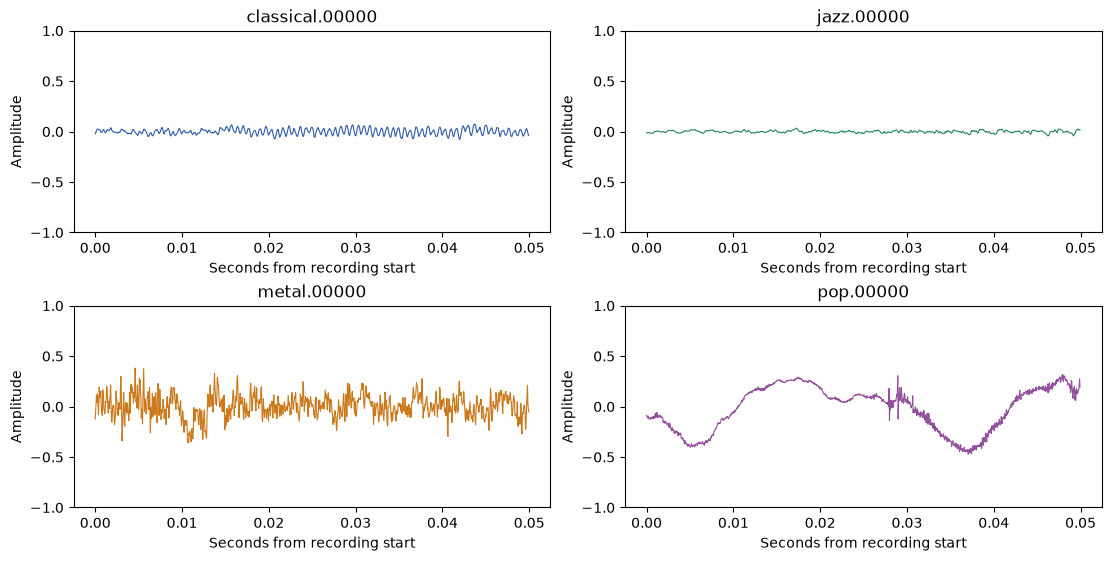

In [4]:
ALL_GENRES = ["blues", "classical", "country", "disco", "hiphop", "jazz", "metal", "pop", "reggae", "rock"]
def audit_dataset(root):
    rows = []
    metadata_files = [str(p.relative_to(root)) for p in sorted(root.rglob("*")) if p.is_file() and is_appledouble(p)]
    for path in audio_files(root):
        directory_genres = set(path.relative_to(root).parts[:-1]) & set(ALL_GENRES)
        genre = next(iter(directory_genres)) if len(directory_genres) == 1 else "unknown"
        row = {"relative_path": str(path.relative_to(root)), "recording_id": path.stem,
               "genre": genre, "sha256": file_hash(path), "bytes": path.stat().st_size,
               "sample_rate": None, "channels": None, "duration": None,
               "frames": None, "decode_status": "failed", "usable": False, "warnings": "", "error": ""}
        warnings = []
        try:
            info = sf.info(path)
            wave, rate = sf.read(path, dtype="float32", always_2d=True)
            row.update(sample_rate=rate, channels=wave.shape[1], frames=len(wave), duration=len(wave)/rate,
                       decoded_pcm_sha256=hashlib.sha256(wave.astype("<f4",copy=False).tobytes()).hexdigest(),
                       minimum=float(wave.min()), maximum=float(wave.max()),
                       rms=float(np.sqrt(np.mean(wave.astype(np.float64)**2))))
            if len(wave) != info.frames or not np.isfinite(wave).all():
                raise ValueError("Frame count mismatch or nonfinite waveform")
            row["decode_status"] = "ok"
            row["usable"] = bool(rate == CFG["sample_rate"] and wave.shape[1] == 1
                                 and len(wave) >= CFG["chunks_per_recording"]*CFG["chunk_samples"]
                                 and path.stem.startswith(genre + "."))
            if rate != 22050: warnings.append("unexpected sample rate")
            if wave.shape[1] != 1: warnings.append("unexpected channel count")
            if not 29 <= len(wave)/rate <= 31: warnings.append("duration outside 29–31 s")
            if not path.stem.startswith(genre + "."): warnings.append("genre/name mismatch")
            if row["rms"] < 1e-6: warnings.append("near-silent")
            if float(np.max(np.abs(wave))) > 1.000001: warnings.append("amplitude outside [-1,1]")
        except (RuntimeError, OSError, ValueError) as error:
            row["error"] = str(error)
        row["warnings"] = "; ".join(warnings)
        rows.append(row)
    frame = pd.DataFrame(rows)
    if frame.empty:
        raise RuntimeError("No recordings found; verify RAW and acquisition cell.")
    frame.to_csv(OUT / "recording_manifest.csv", index=False)
    write_json(OUT / "appledouble_metadata.json", metadata_files)
    return frame
inventory = audit_dataset(RAW)
selected = inventory[inventory.genre.isin(GENRES)].copy().sort_values("recording_id").reset_index(drop=True)
counts = selected.groupby("genre").agg(found=("recording_id", "size"), decoded=("decode_status", lambda s: int((s == "ok").sum())), usable=("usable", "sum")).reindex(GENRES, fill_value=0)
display(counts)
display(inventory.groupby("genre").agg(files=("recording_id","size"), readable=("decode_status",lambda s:int((s=="ok").sum())), min_seconds=("duration","min"), max_seconds=("duration","max")))
problems = inventory[(inventory.decode_status != "ok") | ~inventory.usable | inventory.warnings.ne("")]
print("All audio files:", len(inventory), "| problems/advisories:", len(problems))
display(problems[["relative_path", "genre", "decode_status", "usable", "warnings", "error"]])
duplicate_files = inventory[inventory.duplicated("sha256", keep=False)].sort_values("sha256")
print("Exact-byte duplicate recording files:", len(duplicate_files))
display(duplicate_files[["recording_id", "genre", "sha256"]])
decoded_duplicates = inventory[inventory.decoded_pcm_sha256.notna() & inventory.duplicated("decoded_pcm_sha256",keep=False)]
print("Identical decoded-waveform files (may have different headers):",len(decoded_duplicates))
display(decoded_duplicates[["recording_id","genre","decoded_pcm_sha256"]].sort_values("decoded_pcm_sha256"))
fig, axes = plt.subplots(2, 2, figsize=(11, 5.5), constrained_layout=True)
for genre, ax in zip(GENRES, axes.flat):
    examples = selected[(selected.genre == genre) & selected.usable]
    if examples.empty:
        ax.set_title(genre + ": no usable recording"); continue
    row = examples.iloc[0]
    wave, rate = sf.read(RAW / row.relative_path, dtype="float32")
    n = round(.05*rate)
    ax.plot(np.arange(n)/rate, wave[:n], color=COLORS[genre], linewidth=.8)
    ax.set(title=row.recording_id, xlabel="Seconds from recording start", ylabel="Amplitude", ylim=(-1,1))
fig.savefig(OUT / "native_waveforms.png", dpi=150)
plt.show()
if CFG["audio_playback"]:
    row = selected[selected.usable].iloc[0]
    audio, rate = sf.read(RAW / row.relative_path, dtype="float32")
    display(Audio(audio, rate=rate))


## Phase 2 — Preprocessing and splitting

We require exactly the 400 named source recordings (IDs `.00000` through `.00099` in each selected genre). Each waveform yields 20 adjacent 20,000-sample chunks; each chunk becomes 500 averages of 40 samples. Output shapes are `X=(8000,500)` and integer labels `y=(8000,)`. Metadata retains source file/hash, recording ID, genre, chunk index, original sample boundaries and times.

The cache key includes the actual recording hashes, approved policy and decoder versions. There is no fitted normalization. Assertions catch mismatched labels, nonfinite values, wrong counts, boundary mistakes and pooling errors. If any selected recording is unreadable, resolve its provenance/readability before continuing; this code will not quietly reduce counts.


In [5]:
expected_ids = {f"{genre}.{i:05d}" for genre in GENRES for i in range(100)}
assert set(selected.recording_id) == expected_ids and len(selected) == 400, "Missing/duplicate/unexpected selected recording IDs; inspect manifest."
assert selected.recording_id.is_unique, "Duplicate recording IDs; select one documented source, not a mixture."
assert bool(selected.usable.all()), "Some selected recordings are unusable. No exclusion, repair or padding is authorized by this pipeline."
def pool_recording(wave):
    assert wave.ndim == 1 and len(wave) >= 400000 and np.isfinite(wave).all()
    return wave[:400000].reshape(20, 500, 40).mean(axis=2, dtype=np.float32)
policy = {k:CFG[k] for k in ["sample_rate", "chunks_per_recording", "chunk_samples", "pool_size", "genres"]}
policy.update(interpretation="first-20-consecutive-20000-native-samples", metadata_version=2, dtype="float32", normalization="none",
              numpy=VERSIONS["numpy"], soundfile=VERSIONS["soundfile"], libsndfile=VERSIONS["libsndfile"])
data_signature = fingerprint({"policy":policy, "recordings":selected[["recording_id","genre","sha256"]].to_dict("records")})
CACHE = OUT / "cache" / data_signature[:16]
CACHE.mkdir(parents=True, exist_ok=True)
if (CACHE / "inputs.npz").exists() and (CACHE / "segments.csv").exists() and (CACHE / "config.json").exists():
    assert json.loads((CACHE / "config.json").read_text())["data_signature"] == data_signature
    with np.load(CACHE / "inputs.npz", allow_pickle=False) as cached:
        X, y = cached["X"], cached["y"]
    segments = pd.read_csv(CACHE / "segments.csv")
    print("Loaded verified-configuration cache:", CACHE)
else:
    inputs, labels, metadata = [], [], []
    for row in selected.itertuples():
        wave, rate = sf.read(RAW / row.relative_path, dtype="float32")
        assert rate == 22050 and wave.ndim == 1
        pooled = pool_recording(wave)
        for chunk in range(20):
            start, end = chunk*20000, (chunk+1)*20000
            inputs.append(pooled[chunk]); labels.append(LABELS[row.genre])
            metadata.append({"segment_id":f"{row.recording_id}:chunk{chunk:02d}", "recording_id":row.recording_id,
                "relative_path":row.relative_path, "recording_sha256":row.sha256, "decoded_pcm_sha256":row.decoded_pcm_sha256, "genre":row.genre,
                "label":LABELS[row.genre], "chunk_index":chunk, "start_sample":start, "end_sample_exclusive":end,
                "start_seconds":start/rate, "end_seconds_exclusive":end/rate})
    X, y = np.stack(inputs).astype(np.float32), np.asarray(labels, dtype=np.int64)
    segments = pd.DataFrame(metadata)
    np.savez_compressed(CACHE / "inputs.npz", X=X, y=y)
    segments.to_csv(CACHE / "segments.csv", index=False)
    write_json(CACHE / "config.json", {"data_signature":data_signature, "policy":policy})
assert X.shape == (8000,500) and y.shape == (8000,) and X.dtype == np.float32
assert np.isfinite(X).all() and set(np.unique(y)) == {0,1,2,3}
assert np.array_equal(y, segments.genre.map(LABELS).to_numpy())
assert segments.segment_id.is_unique and (segments.groupby("recording_id").size() == 20).all()
assert (np.bincount(y) == 2000).all()
assert (segments.end_sample_exclusive - segments.start_sample == 20000).all()
assert (segments.start_sample.to_numpy() == segments.chunk_index.to_numpy()*20000).all()
for genre in GENRES:  # hand-check first real segment of every genre, including cached arrays
    i = int(segments.index[segments.genre == genre][0])
    wave, rate = sf.read(RAW / segments.loc[i,"relative_path"], dtype="float32")
    np.testing.assert_allclose(X[i], np.asarray([wave[j:j+40].mean() for j in range(0,20000,40)]), rtol=1e-6, atol=1e-8)
print("Verified", X.shape, "labels", np.bincount(y), "chunk duration", 20000/22050, "seconds")


Loaded verified-configuration cache: /Users/harshak/Documents/GitHub/ML-Mini-Project/artifacts/notebook/cache/79e7f56a9b9c326b
Verified (8000, 500) labels [2000 2000 2000 2000] chunk duration 0.9070294784580499 seconds


### 2.1 Shared example-level split and overlap audit

Shuffle examples with a fixed NumPy seed; take 6,000/1,000/1,000 without stratification (the paper says random, not stratified). All models share these saved indices. No segment ID is duplicated across splits, but **recordings and identical recording content may cross splits**. We report recording-ID, exact-file-hash and decoded-waveform-hash overlap; the last can catch equal audio with different headers. This paper-oriented protocol measures held-out clips, not generalization to unseen recordings. A recording/content-disjoint evaluation would be a separate additional experiment, not a replacement, and is not run here.


In [6]:
split_path = CACHE / f"split_seed_{CFG['seed']}.npz"
if split_path.exists():
    with np.load(split_path, allow_pickle=False) as saved:
        splits = {name:saved[name] for name in ["train","val","test"]}
else:
    shuffled = np.random.default_rng(CFG["seed"]).permutation(len(X))
    splits = {"train":shuffled[:6000], "val":shuffled[6000:7000], "test":shuffled[7000:]}
    np.savez_compressed(split_path, **splits)
assert [len(splits[n]) for n in ["train","val","test"]] == [6000,1000,1000]
assert np.array_equal(np.sort(np.concatenate(list(splits.values()))), np.arange(8000))
split_labels = np.empty(len(X), dtype=object)
for name, indices in splits.items(): split_labels[indices] = name
segments["split"] = split_labels
segments.to_csv(CACHE / f"segments_with_split_seed_{CFG['seed']}.csv", index=False)
display(pd.crosstab(segments.split, segments.genre).reindex(["train","val","test"])[GENRES])
overlap = []
for left, right in [("train","val"),("train","test"),("val","test")]:
    a, b = segments.iloc[splits[left]], segments.iloc[splits[right]]
    overlap.append({"partitions":f"{left}/{right}",
        "shared_segment_ids":len(set(a.segment_id)&set(b.segment_id)),
        "shared_recording_ids":len(set(a.recording_id)&set(b.recording_id)),
        "shared_exact_file_hashes":len(set(a.recording_sha256)&set(b.recording_sha256)),
        "shared_decoded_waveform_hashes":len(set(a.decoded_pcm_sha256)&set(b.decoded_pcm_sha256))})
overlap = pd.DataFrame(overlap)
assert (overlap.shared_segment_ids == 0).all()
# Within each recording chunks are adjacent, nonoverlapping intervals.
ordered = segments.sort_values(["recording_id","start_sample"])
assert all(np.all(g.start_sample.to_numpy()[1:] >= g.end_sample_exclusive.to_numpy()[:-1]) for _,g in ordered.groupby("recording_id"))
display(overlap)
overlap.to_csv(CACHE / "split_overlap.csv", index=False)
split_signature = fingerprint({name:idx.tolist() for name,idx in splits.items()})
print("No repeated segment IDs or overlapping intervals within one recording; shared recordings/content remain leakage risks.")


genre,classical,jazz,metal,pop
split,,,,
train,1508,1484,1488,1520
val,249,242,271,238
test,243,274,241,242


,partitions,shared_segment_ids,shared_recording_ids,shared_exact_file_hashes,shared_decoded_waveform_hashes
0,train/val,0,376,373,367
1,train/test,0,367,364,362
2,val/test,0,344,341,339


No repeated segment IDs or overlapping intervals within one recording; shared recordings/content remain leakage risks.


## Phase 3 — Baseline classifier

The baseline maps `(batch,500)` → tanh hidden `(batch,128)` → raw logits `(batch,4)`. Cross-entropy consumes logits directly. Softmax is used only for reporting probabilities.

The shared trainer below weights epoch averages by the number of examples, including the final short batch. It reports train and validation values in evaluation mode (dropout disabled), while updates use training mode. It selects the checkpoint with lowest validation cross-entropy for the baseline, squared-L2 reconstruction for the AE, and weighted joint objective for the joint model. No test examples are used for optimization or selection. All default Adam parameters and initialization are explicit.

**Long training:** in full mode the following training cells run 200/400/200 epochs. Smoke mode uses one epoch, 256 train examples and 128 validation examples, drawn only from their designated partitions. It verifies code paths, not convergence or paper-level performance. Matching completed checkpoints are reused; smoke/full outputs have separate directories and fingerprints.


In [7]:
X_tensor = torch.from_numpy(X)
y_tensor = torch.from_numpy(y)
fit_indices = splits["train"] if CFG["mode"] == "full" else splits["train"][:CFG["smoke_train_examples"]]
selection_indices = splits["val"] if CFG["mode"] == "full" else splits["val"][:CFG["smoke_val_examples"]]
training_config = {k:v for k,v in CFG.items() if k not in
                   {"project_root","dataset_path","dataset_source","download_if_missing","reuse_checkpoints","force_retrain","evaluate_test","audio_playback"}}
run_spec = {"config":training_config, "versions":VERSIONS, "data_signature":data_signature,
            "split_signature":split_signature, "fit_indices":fit_indices.tolist(),
            "selection_indices":selection_indices.tolist(),
            "selection_rules":{"baseline":"val_cross_entropy","autoencoder":"val_reconstruction","joint":"val_total"}}
RUN_ID = fingerprint(run_spec)
RUN = OUT / CFG["mode"] / RUN_ID[:16]
RUN.mkdir(parents=True, exist_ok=True)
write_json(RUN / "run_config.json", run_spec)
def make_loader(indices, shuffle=False, seed=0):
    dataset = TensorDataset(X_tensor[indices], y_tensor[indices])
    generator = torch.Generator().manual_seed(seed)
    return DataLoader(dataset, batch_size=CFG["batch_size"], shuffle=shuffle, generator=generator, num_workers=0)
def initialize(module):
    if isinstance(module, nn.Linear):
        nn.init.xavier_uniform_(module.weight); nn.init.zeros_(module.bias)
def optimizer_for(model):
    return torch.optim.Adam(model.parameters(), lr=CFG["learning_rate"], betas=tuple(CFG["adam_betas"]),
                            eps=CFG["adam_epsilon"], weight_decay=CFG["weight_decay"])
def reconstruction_loss(reconstruction, target):
    return (reconstruction-target).square().sum(dim=1).mean()
cross_entropy = nn.CrossEntropyLoss(reduction="mean")
def losses_for(output, inputs, labels, kind):
    result = {}
    if "reconstruction" in output:
        result["reconstruction"] = reconstruction_loss(output["reconstruction"], inputs)
    if "logits" in output:
        result["cross_entropy"] = cross_entropy(output["logits"], labels)
    if kind == "joint":
        result["weighted_reconstruction"] = CFG["gamma"]*result["reconstruction"]
        result["weighted_classification"] = (1-CFG["gamma"])*result["cross_entropy"]
        result["total"] = result["weighted_reconstruction"] + result["weighted_classification"]
    else:
        result["total"] = result["cross_entropy" if kind == "baseline" else "reconstruction"]
    return result
def epoch_pass(model, loader, kind, optimizer=None):
    model.train(optimizer is not None)
    totals, count, correct = {}, 0, 0
    with torch.set_grad_enabled(optimizer is not None):
        for inputs, labels in loader:
            inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
            if optimizer is not None: optimizer.zero_grad(set_to_none=True)
            output = model(inputs)
            losses = losses_for(output, inputs, labels, kind)
            if not all(torch.isfinite(value).item() for value in losses.values()):
                raise FloatingPointError("Nonfinite loss; inspect config/data before continuing.")
            if optimizer is not None:
                losses["total"].backward()
                if not all(torch.isfinite(p.grad).all() for p in model.parameters() if p.grad is not None):
                    raise FloatingPointError("Nonfinite gradient")
                optimizer.step()
            batch_count = len(inputs); count += batch_count
            for name, value in losses.items(): totals[name] = totals.get(name,0.0) + value.item()*batch_count
            if "logits" in output: correct += int((output["logits"].argmax(1)==labels).sum())
    result = {name:value/count for name,value in totals.items()}
    if "cross_entropy" in result: result["accuracy"] = correct/count
    return result
def load_saved_model(factory, name):
    metadata = json.loads((RUN / f"{name}_checkpoint.json").read_text())
    path = RUN / f"{name}.pt"
    assert metadata["run_id"] == RUN_ID and metadata["training_completed"]
    assert metadata["checkpoint_sha256"] == file_hash(path), "Checkpoint changed since verification."
    model = factory().to(DEVICE)
    model.load_state_dict(torch.load(path, map_location=DEVICE, weights_only=True))
    model.eval()
    return model
def train_or_load(factory, name):
    if CFG["force_retrain"] and (RUN/"final_test_freeze.json").exists():
        raise RuntimeError("This run has already opened test. Use a documented new experiment/version for any retraining.")
    seed = CFG["seed"] + {"baseline":0,"autoencoder":1,"joint":2}[name]
    seed_everything(seed)
    path, meta_path = RUN/f"{name}.pt", RUN/f"{name}_checkpoint.json"
    if CFG["reuse_checkpoints"] and not CFG["force_retrain"] and path.exists() and meta_path.exists():
        metadata = json.loads(meta_path.read_text())
        if metadata.get("training_completed") and metadata.get("run_id") == RUN_ID:
            model = load_saved_model(factory, name)
            history = pd.read_csv(RUN/f"{name}_history.csv")
            print("Loaded", name, "best epoch", metadata["best_epoch"], "from", path)
            return model, history
    if (RUN/"final_test_freeze.json").exists():
        raise RuntimeError("A frozen final-test run has missing/incomplete checkpoints; restore its artifacts, do not retrain silently.")
    model = factory().to(DEVICE)
    optimizer = optimizer_for(model)
    train_loader = make_loader(fit_indices, shuffle=True, seed=seed)
    train_eval_loader, val_loader = make_loader(fit_indices), make_loader(selection_indices)
    epochs = CFG["full_epochs"][name] if CFG["mode"] == "full" else CFG["smoke_epochs"]
    best_value, best_epoch, history = math.inf, None, []
    write_json(meta_path, {"run_id":RUN_ID, "training_completed":False, "seed":seed})
    began = time.monotonic()
    for epoch in range(1, epochs+1):
        update_metrics = epoch_pass(model, train_loader, name, optimizer)
        train_metrics = epoch_pass(model, train_eval_loader, name)
        val_metrics = epoch_pass(model, val_loader, name)
        row = {"epoch":epoch, "update_total":update_metrics["total"],
               **{f"train_{k}":v for k,v in train_metrics.items()},
               **{f"val_{k}":v for k,v in val_metrics.items()}}
        history.append(row)
        if val_metrics["total"] < best_value:
            best_value, best_epoch = val_metrics["total"], epoch
            state = {k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
            torch.save(state, path)
        if epoch == 1 or epoch % 25 == 0 or epoch == epochs:
            print(f"{name} | {CFG['mode']} | epoch {epoch}/{epochs} | train {train_metrics['total']:.6f} | val {val_metrics['total']:.6f}", flush=True)
    history = pd.DataFrame(history)
    history.to_csv(RUN/f"{name}_history.csv", index=False)
    write_json(meta_path, {"run_id":RUN_ID, "mode":CFG["mode"], "training_completed":True,
        "epochs_executed":epochs, "seed":seed, "best_epoch":best_epoch, "best_val_total":best_value,
        "selection_rule":run_spec["selection_rules"][name], "checkpoint_sha256":file_hash(path),
        "elapsed_seconds":time.monotonic()-began, "created_at_utc":datetime.now(timezone.utc).isoformat()})
    return load_saved_model(factory,name), history
@torch.inference_mode()
def representations(model, indices):
    model.eval()
    collected = {}
    for inputs, _ in make_loader(indices):
        for key, value in model(inputs.to(DEVICE)).items():
            collected.setdefault(key,[]).append(value.cpu().numpy())
    return {key:np.concatenate(parts) for key,parts in collected.items()}
def save_representations(name, partition, indices, values):
    assert all(len(array)==len(indices) and np.isfinite(array).all() for array in values.values())
    np.savez_compressed(RUN/f"{name}_{partition}_representations.npz", indices=indices,
                        segment_ids=segments.iloc[indices].segment_id.to_numpy(dtype=str), **values)
def check_model(model, kind):
    # Real training examples, separate disposable model. Not an experimental run.
    model = model.to(DEVICE); model.train()
    inputs, labels = X_tensor[splits["train"][:8]].to(DEVICE), y_tensor[splits["train"][:8]].to(DEVICE)
    output = model(inputs)
    if kind != "autoencoder": assert output["logits"].shape == (8,4)
    if kind != "baseline":
        assert output["embedding"].shape == (8,64) and output["reconstruction"].shape == (8,500)
    optimizer = optimizer_for(model)
    before = [p.detach().clone() for p in model.parameters()]
    optimizer.zero_grad(); losses = losses_for(output,inputs,labels,kind)
    losses["total"].backward()
    assert any(p.grad is not None and p.grad.abs().sum().item()>0 for p in model.parameters())
    assert all(torch.isfinite(p.grad).all() for p in model.parameters() if p.grad is not None)
    if kind == "joint":
        assert any(p.grad is not None and p.grad.abs().sum().item()>0 for p in model.ae.encoder.parameters())
        assert any(p.grad is not None and p.grad.abs().sum().item()>0 for p in model.classifier.parameters())
        torch.testing.assert_close(losses["total"], CFG["gamma"]*losses["reconstruction"]+(1-CFG["gamma"])*losses["cross_entropy"])
    optimizer.step()
    assert any(not torch.equal(a,b) for a,b in zip(before,model.parameters()))
    model.eval()
    with torch.no_grad():
        a,b = model(inputs), model(inputs)
        for key in a: torch.testing.assert_close(a[key],b[key])
    print(kind, "shape/loss/gradient/training-step/eval-repeatability checks passed")

# Hand-calculated mathematical checks, not synthetic replacements for audio.
assert reconstruction_loss(torch.ones(2,500),torch.zeros(2,500)).item() == 500
assert reconstruction_loss(torch.ones(7,500),torch.zeros(7,500)).item() == 500
torch.testing.assert_close(cross_entropy(torch.zeros(2,4),torch.tensor([0,3])),torch.tensor(math.log(4)))
class BaselineClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(nn.Linear(500,128),nn.Tanh(),nn.Linear(128,4))
        self.apply(initialize)
    def forward(self, inputs): return {"logits":self.network(inputs)}
check_model(BaselineClassifier(), "baseline")


baseline shape/loss/gradient/training-step/eval-repeatability checks passed


### 3.1 Train or load the baseline

This cell executes the configured training budget or loads a verified matching checkpoint. The CSV records real training/validation losses and accuracies; the checkpoint metadata records the selected epoch. A completed **smoke** checkpoint means only that the smoke run finished.


In [8]:
baseline, baseline_history = train_or_load(BaselineClassifier, "baseline")
display(baseline_history.tail())


Loaded baseline best epoch 1 from /Users/harshak/Documents/GitHub/ML-Mini-Project/artifacts/notebook/smoke/26ec28f80802fd19/baseline.pt


,epoch,update_total,train_cross_entropy,train_total,train_accuracy,val_cross_entropy,val_total,val_accuracy
0,1,1.413584,1.409952,1.409952,0.28125,1.40485,1.40485,0.273438


## Phase 4 — Vanilla autoencoder

The encoder compresses `(batch,500)` into `(batch,64)`; the decoder returns `(batch,500)`. It sees no classification loss. Activation and dropout placement come from the authors' code; probability .1 follows the paper rather than source .2. The source's **ReLU output** is retained and cannot reproduce negative input samples, so reconstruction plots and losses must be interpreted with this constraint. A linear-output variant would be an explicitly separate deviation, not silently substituted here.


In [9]:
def activation(name):
    return {"sigmoid":nn.Sigmoid, "tanh":nn.Tanh, "relu":nn.ReLU}[name]()
def dense_stack(widths, activation_names):
    layers = []
    for left,right,nonlinearity in zip(widths[:-1],widths[1:],activation_names):
        layers.extend([nn.Linear(left,right),activation(nonlinearity)])
        if right == CFG["dropout_after_width"]:
            layers.append(nn.Dropout(CFG["dropout_probability"]))
    return nn.Sequential(*layers)
class VanillaAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = dense_stack([500,256,192,128,64],CFG["encoder_activations"])
        self.decoder = dense_stack([64,128,192,256,500],CFG["decoder_activations"])
        self.apply(initialize)
    def forward(self,inputs):
        embedding = self.encoder(inputs)
        return {"embedding":embedding,"reconstruction":self.decoder(embedding)}
check_model(VanillaAutoencoder(), "autoencoder")


autoencoder shape/loss/gradient/training-step/eval-repeatability checks passed


### 4.1 Train and inspect reconstructions

The full budget is 400 epochs. We export training/validation embeddings with segment IDs and inspect a validation reconstruction. The plotted 500 values are pooled amplitudes, not a reconstructed full-bandwidth audio file. The reported squared-L2 is summed over 500 dimensions; elementwise MSE is shown separately by dividing by 500.


Loaded autoencoder best epoch 1 from /Users/harshak/Documents/GitHub/ML-Mini-Project/artifacts/notebook/smoke/26ec28f80802fd19/autoencoder.pt


smoke validation squared-L2: 33.12701846313477 elementwise MSE: 0.06625403692626954


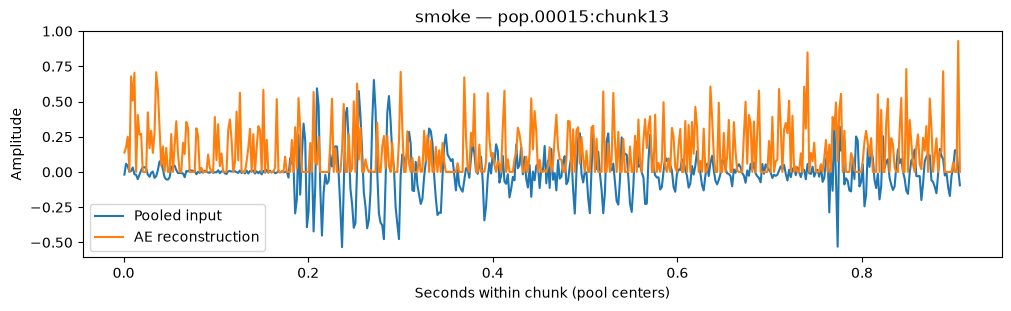

In [10]:
autoencoder, ae_history = train_or_load(VanillaAutoencoder, "autoencoder")
ae_representations = {name:representations(autoencoder,splits[name]) for name in ["train","val"]}
for name,values in ae_representations.items():
    assert values["embedding"].shape == (len(splits[name]),64)
    save_representations("autoencoder",name,splits[name],values)
i = int(splits["val"][0])
reconstructed = ae_representations["val"]["reconstruction"][0]
batch_sse = np.square(ae_representations["val"]["reconstruction"]-X[splits["val"]]).sum(axis=1).mean()
metrics = epoch_pass(autoencoder,make_loader(splits["val"]),"autoencoder")
np.testing.assert_allclose(batch_sse,metrics["reconstruction"],rtol=1e-5)
print(CFG["mode"], "validation squared-L2:", metrics["reconstruction"], "elementwise MSE:",metrics["reconstruction"]/500)
fig,ax = plt.subplots(figsize=(10,3), constrained_layout=True)
t = (np.arange(500)*40 + 19.5)/22050
ax.plot(t,X[i],label="Pooled input"); ax.plot(t,reconstructed,label="AE reconstruction")
ax.set(xlabel="Seconds within chunk (pool centers)",ylabel="Amplitude",title=f"{CFG['mode']} — {segments.loc[i,'segment_id']}")
ax.legend(); fig.savefig(RUN/"ae_reconstruction.png",dpi=150); plt.show()


## Phase 5 — Deep Softmax Autoencoder

The same 64-dimensional embedding feeds a 64→32 tanh→16 tanh→4 linear classifier. Reconstruction and classification update the shared encoder together. The loss is `.9 × batch-mean squared-L2 + .1 × batch-mean CE`; raw and weighted components are logged separately. Dropout belongs to the encoder/decoder, not the classification head.


In [11]:
class DeepSoftmaxAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.ae = VanillaAutoencoder()
        self.classifier = nn.Sequential(nn.Linear(64,32),activation(CFG["head_activations"][0]),
                                        nn.Linear(32,16),activation(CFG["head_activations"][1]),nn.Linear(16,4))
        self.classifier.apply(initialize)
    def forward(self,inputs):
        output = self.ae(inputs)
        output["logits"] = self.classifier(output["embedding"])
        return output
check_model(DeepSoftmaxAutoencoder(), "joint")


joint shape/loss/gradient/training-step/eval-repeatability checks passed


### 5.1 Joint training and representation export

The full budget is 200 epochs. Expect raw reconstruction, cross-entropy, weighted components, total loss and accuracy for train/validation in the history. Exported logits are pre-softmax `(N,4)`; embeddings are `(N,64)`. Neither training nor these exports inspect test examples.


In [12]:
joint, joint_history = train_or_load(DeepSoftmaxAutoencoder, "joint")
for prefix in ["train","val"]:
    np.testing.assert_allclose(joint_history[f"{prefix}_total"],
        CFG["gamma"]*joint_history[f"{prefix}_reconstruction"]+(1-CFG["gamma"])*joint_history[f"{prefix}_cross_entropy"],rtol=1e-5)
joint_representations = {name:representations(joint,splits[name]) for name in ["train","val"]}
baseline_representations = {name:representations(baseline,splits[name]) for name in ["train","val"]}
for name in ["train","val"]:
    assert joint_representations[name]["embedding"].shape == (len(splits[name]),64)
    assert joint_representations[name]["logits"].shape == (len(splits[name]),4)
    save_representations("joint",name,splits[name],joint_representations[name])
    save_representations("baseline",name,splits[name],baseline_representations[name])
display(joint_history.tail())


Loaded joint best epoch 1 from /Users/harshak/Documents/GitHub/ML-Mini-Project/artifacts/notebook/smoke/26ec28f80802fd19/joint.pt


,epoch,update_total,train_reconstruction,train_cross_entropy,train_weighted_reconstruction,train_weighted_classification,train_total,train_accuracy,val_reconstruction,val_cross_entropy,val_weighted_reconstruction,val_weighted_classification,val_total,val_accuracy
0,1,18.258932,17.061888,1.391343,15.355699,0.139134,15.494833,0.253906,18.030455,1.384528,16.227409,0.138453,16.365862,0.304688


## Phase 6 — Evaluation and visualization

### 6.1 Freeze choices before final test evaluation

By default evaluate training and validation only. In smoke mode all metrics and plots are diagnostic. For a full experiment, first run with `mode="full", evaluate_test=False`; review validation results, finalize choices, then set `evaluate_test=True` and rerun using the saved checkpoints. The cell records all three checkpoint hashes before opening test and reuses saved final test outputs on subsequent analysis runs. Do not use test outcomes to tune this run.

Metrics use `model.eval()` and no gradients. Classifier outputs are `(N,4)` logits; autoencoder reconstructions are `(N,500)`. Accuracy and per-class precision/recall/F1 are computed only for classifiers. Reconstruction metrics are reported for both autoencoders. A smoke run's “train” metrics describe the 6,000-example training partition although only the configured 256 examples were used for its updates; the table labels this explicitly.


In [13]:
models = {"baseline":baseline, "autoencoder":autoencoder, "joint":joint}
all_representations = {"baseline":baseline_representations, "autoencoder":ae_representations, "joint":joint_representations}
evaluated_partitions = ["train","val"]
if CFG["evaluate_test"]:
    assert CFG["mode"] == "full"
    freeze = {"run_id":RUN_ID, "checkpoint_hashes":{name:file_hash(RUN/f"{name}.pt") for name in models}}
    for name in models:
        record = json.loads((RUN/f"{name}_checkpoint.json").read_text())
        assert record["mode"] == "full" and record["training_completed"]
        assert record["epochs_executed"] == CFG["full_epochs"][name]
    freeze_path = RUN/"final_test_freeze.json"
    if freeze_path.exists():
        assert json.loads(freeze_path.read_text()) == freeze, "Frozen checkpoints changed after test was opened."
    else:
        write_json(freeze_path,freeze)
    for name,model in models.items():
        saved_path = RUN/f"{name}_test_representations.npz"
        if saved_path.exists():
            with np.load(saved_path,allow_pickle=False) as saved:
                assert np.array_equal(saved["indices"],splits["test"])
                values = {key:saved[key] for key in saved.files if key not in {"indices","segment_ids"}}
        else:
            values = representations(model,splits["test"])
            save_representations(name,"test",splits["test"],values)
        all_representations[name]["test"] = values
    evaluated_partitions.append("test")
else:
    print("Test set remains unevaluated. All held-out plots/demo use validation.")

metric_rows, reports = [], {}
for name in models:
    for partition in evaluated_partitions:
        indices = splits[partition]; values = all_representations[name][partition]
        row = {"run_mode":CFG["mode"], "model":name, "partition":partition, "examples":len(indices),
               "training_examples_used":len(fit_indices), "validation_examples_for_selection":len(selection_indices)}
        if "logits" in values:
            logits = torch.from_numpy(values["logits"])
            predicted = logits.argmax(1).numpy()
            row["accuracy"] = accuracy_score(y[indices],predicted)
            row["cross_entropy"] = cross_entropy(logits,torch.from_numpy(y[indices])).item()
            report = classification_report(y[indices],predicted,labels=np.arange(4),target_names=GENRES,output_dict=True,zero_division=0)
            reports[f"{name}_{partition}"] = report
        if "reconstruction" in values:
            error = values["reconstruction"]-X[indices]
            row["reconstruction_squared_l2"] = float(np.square(error).sum(1).mean())
            row["reconstruction_elementwise_mse"] = row["reconstruction_squared_l2"]/500
        if name == "joint":
            row["joint_total"] = CFG["gamma"]*row["reconstruction_squared_l2"]+(1-CFG["gamma"])*row["cross_entropy"]
        metric_rows.append(row)
metrics_table = pd.DataFrame(metric_rows)
metrics_table.to_csv(RUN/"metrics.csv",index=False)
write_json(RUN/"classification_reports.json",reports)
display(metrics_table)
HELDOUT = "test" if CFG["evaluate_test"] else "val"
for name in ["baseline","joint"]:
    print(CFG["mode"],name,HELDOUT,"per-class metrics (undefined precision/recall handled as zero)")
    display(pd.DataFrame(reports[f"{name}_{HELDOUT}"]).T)


Test set remains unevaluated. All held-out plots/demo use validation.


,run_mode,model,partition,examples,training_examples_used,validation_examples_for_selection,accuracy,cross_entropy,reconstruction_squared_l2,reconstruction_elementwise_mse,joint_total
0,smoke,baseline,train,6000,256,128,0.261833,1.397591,NaN,NaN,NaN
1,smoke,baseline,val,1000,256,128,0.264000,1.393104,NaN,NaN,NaN
2,smoke,autoencoder,train,6000,256,128,NaN,NaN,33.191360,0.066383,NaN
3,smoke,autoencoder,val,1000,256,128,NaN,NaN,33.127018,0.066254,NaN
4,smoke,joint,train,6000,256,128,0.247833,1.403334,17.385727,0.034771,15.787488
5,smoke,joint,val,1000,256,128,0.271000,1.396445,17.339964,0.034680,15.745612


smoke baseline val per-class metrics (undefined precision/recall handled as zero)


,precision,recall,f1-score,support
classical,0.266917,0.285141,0.275728,249.000
jazz,0.219512,0.223140,0.221311,242.000
metal,0.290598,0.250923,0.269307,271.000
pop,0.279528,0.298319,0.288618,238.000
accuracy,0.264000,0.264000,0.264000,0.264
macro avg,0.264139,0.264381,0.263741,1000.000
weighted avg,0.264864,0.264000,0.263887,1000.000


smoke joint val per-class metrics (undefined precision/recall handled as zero)


,precision,recall,f1-score,support
classical,0.000000,0.000,0.000000,249.000
jazz,0.000000,0.000,0.000000,242.000
metal,0.271271,1.000,0.426772,271.000
pop,0.000000,0.000,0.000000,238.000
accuracy,0.271000,0.271,0.271000,0.271
macro avg,0.067818,0.250,0.106693,1000.000
weighted avg,0.073515,0.271,0.115655,1000.000


### 6.2 Curves and confusion matrices

Training and validation curves help reveal overfitting: improving training accuracy with stagnant validation accuracy is a warning. One-epoch smoke curves cannot establish a trend. Loss components use their documented units; reconstruction squared-L2 and cross-entropy have different scales. Confusion-matrix rows are true genres and columns predicted genres; raw counts make supports visible. These are actual computed outputs, never the paper's matrices.


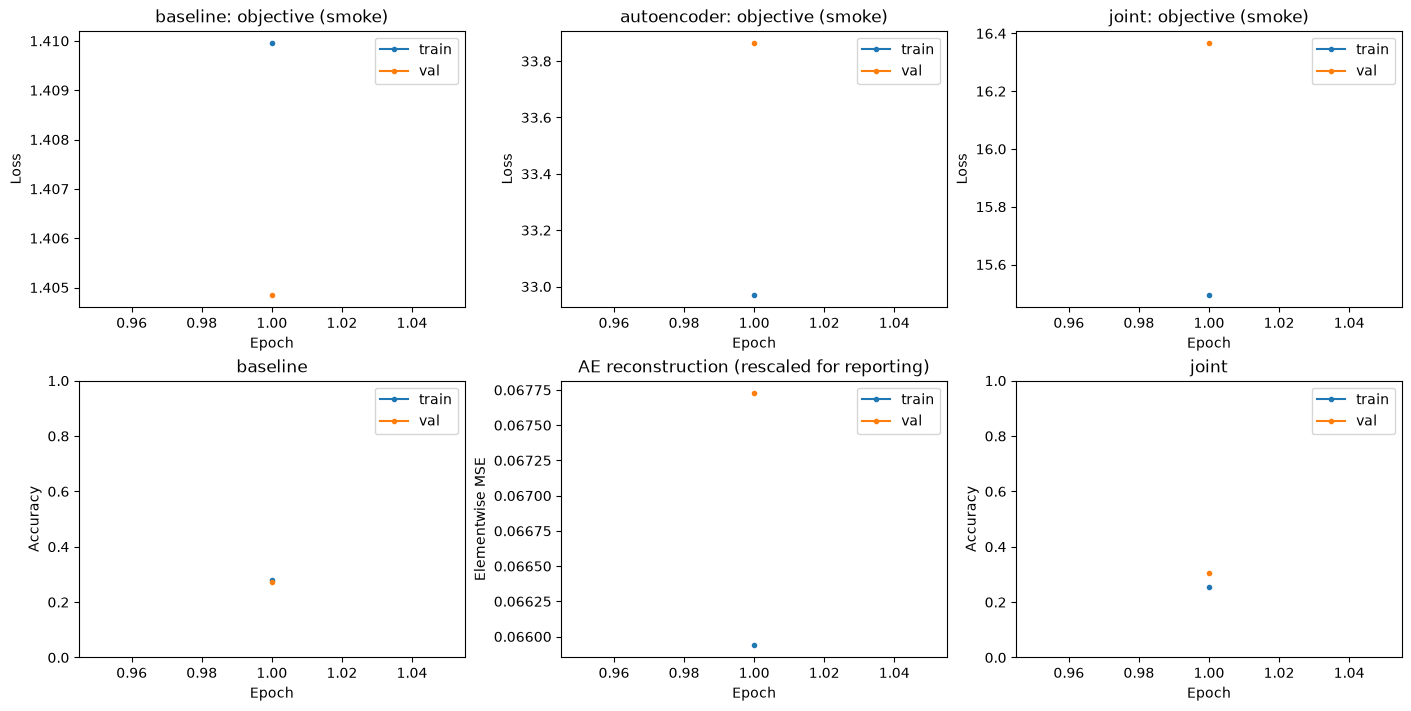

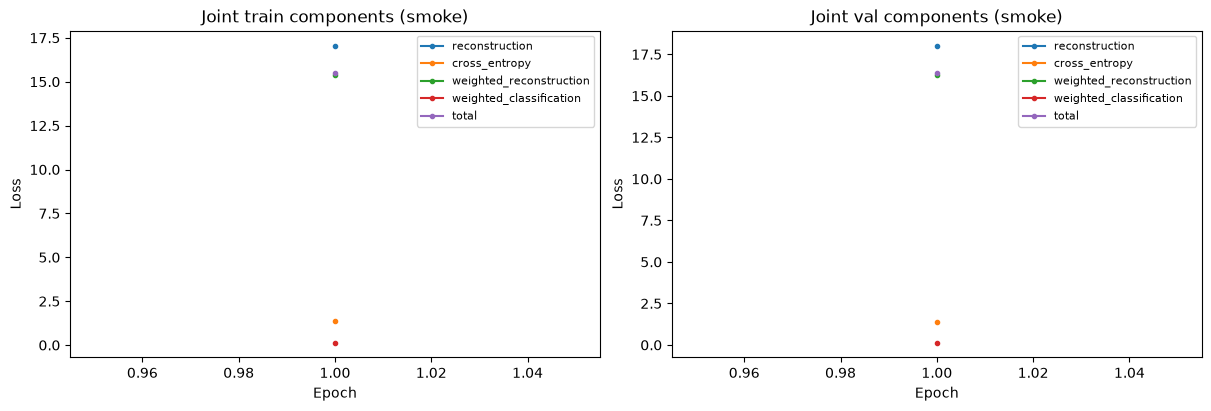

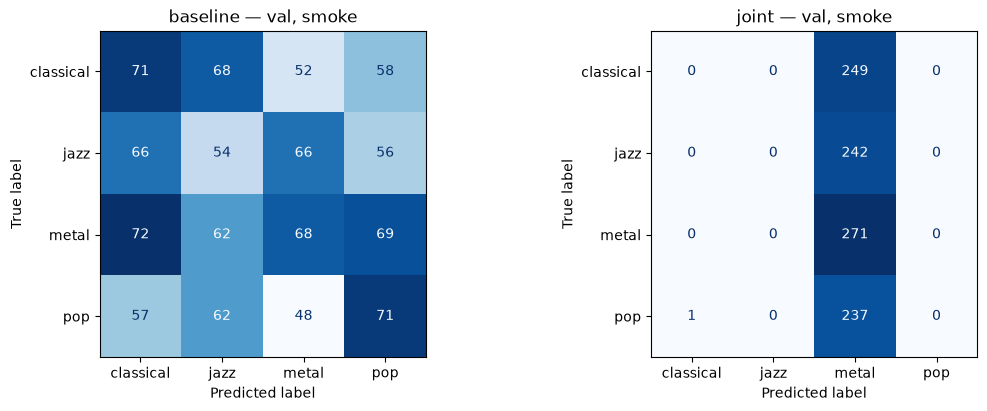

In [14]:
histories = {"baseline":baseline_history,"autoencoder":ae_history,"joint":joint_history}
fig,axes = plt.subplots(2,3,figsize=(14,7),constrained_layout=True)
for col,(name,history) in enumerate(histories.items()):
    for partition in ["train","val"]:
        axes[0,col].plot(history.epoch,history[f"{partition}_total"],marker=".",label=partition)
    axes[0,col].set(title=f"{name}: objective ({CFG['mode']})",xlabel="Epoch",ylabel="Loss"); axes[0,col].legend()
    if name == "autoencoder":
        for partition in ["train","val"]:
            axes[1,col].plot(history.epoch,history[f"{partition}_reconstruction"]/500,marker=".",label=partition)
        axes[1,col].set(ylabel="Elementwise MSE",title="AE reconstruction (rescaled for reporting)")
    else:
        for partition in ["train","val"]:
            axes[1,col].plot(history.epoch,history[f"{partition}_accuracy"],marker=".",label=partition)
        axes[1,col].set(ylabel="Accuracy",ylim=(0,1),title=name)
    axes[1,col].set_xlabel("Epoch"); axes[1,col].legend()
fig.savefig(RUN/"training_curves.png",dpi=150); plt.show()
fig,axes = plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
for partition,ax in zip(["train","val"],axes):
    for key in ["reconstruction","cross_entropy","weighted_reconstruction","weighted_classification","total"]:
        ax.plot(joint_history.epoch,joint_history[f"{partition}_{key}"],marker=".",label=key)
    ax.set(title=f"Joint {partition} components ({CFG['mode']})",xlabel="Epoch",ylabel="Loss"); ax.legend(fontsize=8)
fig.savefig(RUN/"joint_loss_components.png",dpi=150); plt.show()
fig,axes = plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
for name,ax in zip(["baseline","joint"],axes):
    pred = all_representations[name][HELDOUT]["logits"].argmax(1)
    matrix = confusion_matrix(y[splits[HELDOUT]],pred,labels=np.arange(4))
    assert matrix.sum() == len(splits[HELDOUT])
    ConfusionMatrixDisplay(matrix,display_labels=GENRES).plot(ax=ax,colorbar=False,cmap="Blues",values_format="d")
    ax.set_title(f"{name} — {HELDOUT}, {CFG['mode']}")
    pd.DataFrame(matrix,index=GENRES,columns=GENRES).to_csv(RUN/f"{name}_{HELDOUT}_confusion.csv")
fig.savefig(RUN/f"confusion_{HELDOUT}.png",dpi=150); plt.show()


### 6.3 PCA of inputs, embeddings and logits

PCA rotates high-dimensional data to display two directions with high variance. We fit **each projection only on training representations**, then transform the same held-out partition for all plots. The models share split indices, but PCA axes from different representation spaces are not directly numerically comparable. Colors are consistent across genres. Apparent clusters do not prove style understanding, and the reported recording/content overlap limits independence.

We plot all five requested views: processed inputs, AE 64-dimensional embeddings, joint 64-dimensional embeddings, baseline four-dimensional logits, and joint four-dimensional logits. PCA parameters are saved with their training-data provenance; no learned preprocessing is fitted on validation or test.


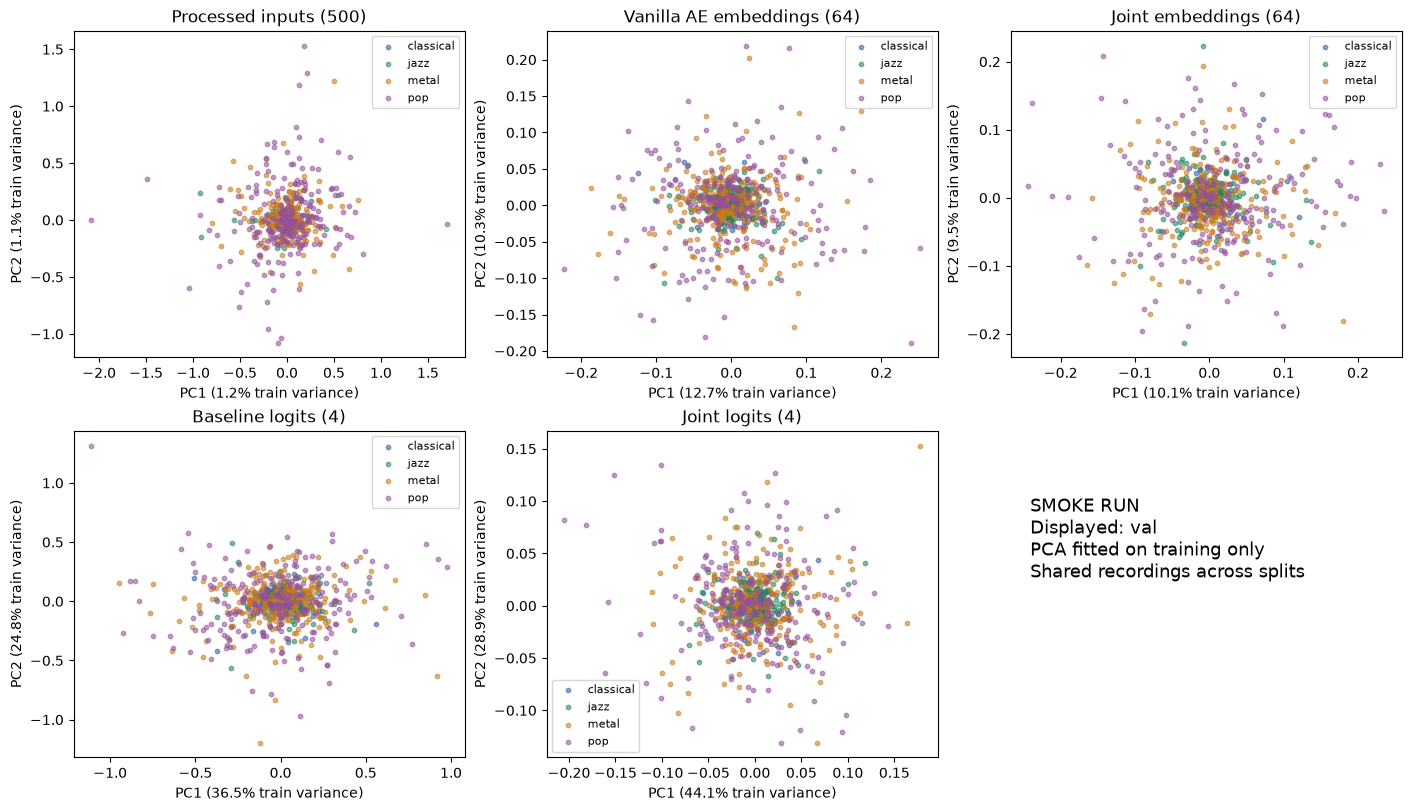

In [15]:
spaces = {
    "Processed inputs (500)":(X[splits["train"]],X[splits[HELDOUT]]),
    "Vanilla AE embeddings (64)":(all_representations["autoencoder"]["train"]["embedding"],all_representations["autoencoder"][HELDOUT]["embedding"]),
    "Joint embeddings (64)":(all_representations["joint"]["train"]["embedding"],all_representations["joint"][HELDOUT]["embedding"]),
    "Baseline logits (4)":(all_representations["baseline"]["train"]["logits"],all_representations["baseline"][HELDOUT]["logits"]),
    "Joint logits (4)":(all_representations["joint"]["train"]["logits"],all_representations["joint"][HELDOUT]["logits"]),
}
fig,axes = plt.subplots(2,3,figsize=(14,8),constrained_layout=True)
pca_summary = []
for number,((title,(train_space,heldout_space)),ax) in enumerate(zip(spaces.items(),axes.flat)):
    pca = PCA(n_components=2,svd_solver="full")
    pca.fit(train_space)
    coordinates = pca.transform(heldout_space)
    assert coordinates.shape == (len(splits[HELDOUT]),2) and np.isfinite(coordinates).all()
    for genre in GENRES:
        mask = y[splits[HELDOUT]] == LABELS[genre]
        ax.scatter(coordinates[mask,0],coordinates[mask,1],s=10,alpha=.55,color=COLORS[genre],label=genre)
    ratios = pca.explained_variance_ratio_
    ax.set(title=title,xlabel=f"PC1 ({ratios[0]:.1%} train variance)",ylabel=f"PC2 ({ratios[1]:.1%} train variance)")
    ax.legend(fontsize=8)
    np.savez_compressed(RUN/f"pca_{number}.npz",mean=pca.mean_,components=pca.components_,
                        explained_variance_ratio=ratios,heldout_coordinates=coordinates,heldout_indices=splits[HELDOUT])
    pca_summary.append({"space":title,"fit_partition":"train","display_partition":HELDOUT,"explained_variance_ratio":ratios.tolist()})
axes.flat[-1].axis("off")
axes.flat[-1].text(.05,.8,f"{CFG['mode'].upper()} RUN\nDisplayed: {HELDOUT}\nPCA fitted on training only\nShared recordings across splits",fontsize=13,va="top")
fig.savefig(RUN/f"pca_{HELDOUT}.png",dpi=150); plt.show()
write_json(RUN/"pca_summary.json",pca_summary)


## Phase 7 — Demonstration and discussion

### 7.1 Load a saved model and predict a held-out clip

This cell reloads the verified joint checkpoint, predicts the first fixed held-out clip and displays its true genre, prediction and four softmax probabilities. In development/smoke runs the clip comes from validation; after final evaluation it comes from test. A held-out clip can still share a recording with training. Optional playback uses the original 20,000 samples, not pooled vectors. Softmax values are model outputs, not guaranteed calibrated confidence.


In [16]:
demo_model = load_saved_model(DeepSoftmaxAutoencoder,"joint")
demo_index = int(splits[HELDOUT][0])
demo_row = segments.iloc[demo_index]
with torch.inference_mode():
    demo_logits = demo_model(X_tensor[demo_index:demo_index+1].to(DEVICE))["logits"]
    probabilities = torch.softmax(demo_logits,dim=1)[0].cpu().numpy()
assert np.isclose(probabilities.sum(),1.0)
demo_result = {"run_mode":CFG["mode"],"partition":HELDOUT,"segment_id":demo_row.segment_id,
               "true_genre":demo_row.genre,"predicted_genre":GENRES[int(probabilities.argmax())],
               "probabilities":{genre:float(probabilities[i]) for i,genre in enumerate(GENRES)}}
display(pd.Series({k:v for k,v in demo_result.items() if k != "probabilities"}))
display(pd.DataFrame({"genre":GENRES,"probability":probabilities}))
write_json(RUN/"demo_prediction.json",demo_result)
if CFG["audio_playback"]:
    waveform,rate = sf.read(RAW/demo_row.relative_path,dtype="float32")
    display(Audio(waveform[int(demo_row.start_sample):int(demo_row.end_sample_exclusive)],rate=rate))


run_mode                       smoke
partition                        val
segment_id         pop.00015:chunk13
true_genre                       pop
predicted_genre                metal
dtype: str

,genre,probability
0,classical,0.280236
1,jazz,0.200535
2,metal,0.320482
3,pop,0.198747


### 7.2 Actual results versus the paper

The next cell prints the paper table separately from computed results. In smoke mode computed accuracies are diagnostics only and are not reproduction results. Test rows exist only after final evaluation was explicitly enabled. Examine common off-diagonal confusions and a fixed list of misclassified held-out clips. Do not use test error examples to retune this finalized run.


In [17]:
reference_results = pd.DataFrame([
    {"source":"Paper Table 1, p.3","model":"baseline","train_accuracy":.520,"val_accuracy":.381,"test_accuracy":.364},
    {"source":"Paper Table 1, p.3","model":"joint","train_accuracy":.949,"val_accuracy":.641,"test_accuracy":.653},
])
print("REFERENCE RESULTS — not values produced by this notebook")
display(reference_results)
print("ACTUAL", CFG["mode"].upper(), "RUN —", "diagnostics only" if CFG["mode"] == "smoke" else "measured full-budget experiment")
actual_accuracy = metrics_table[metrics_table.model.isin(["baseline","joint"])].pivot(index="model",columns="partition",values="accuracy")
display(actual_accuracy)
differences = []
if CFG["mode"] == "full":
    for row in reference_results.itertuples():
        for partition in evaluated_partitions:
            observed = float(actual_accuracy.loc[row.model,partition])
            differences.append({"model":row.model,"partition":partition,"actual_accuracy":observed,
                                "paper_accuracy":getattr(row,f"{partition}_accuracy"),
                                "difference_percentage_points":100*(observed-getattr(row,f"{partition}_accuracy"))})
    display(pd.DataFrame(differences))
predictions = all_representations["joint"][HELDOUT]["logits"].argmax(1)
errors = segments.iloc[splits[HELDOUT]].copy()
errors["prediction"] = [GENRES[i] for i in predictions]
errors = errors[errors.genre != errors.prediction]
print("Joint errors:",len(errors),"of",len(splits[HELDOUT]),"held-out clips")
display(errors[["segment_id","genre","prediction","start_seconds"]].head(12))
error_pairs = errors.groupby(["genre","prediction"]).size().sort_values(ascending=False).rename("count")
display(error_pairs.head(6))
errors.to_csv(RUN/f"joint_{HELDOUT}_errors.csv",index=False)
if CFG["mode"] == "smoke":
    print("No convergence or overfitting conclusion is supported by this short smoke run. Full experiments remain to be executed.")
else:
    for name in ["baseline","joint"]:
        gap = float(actual_accuracy.loc[name,"train"]-actual_accuracy.loc[name,"val"])
        print(f"{name}: measured train-minus-validation accuracy gap = {100*gap:.2f} percentage points.")
print("Saved run artifacts:", RUN)


REFERENCE RESULTS — not values produced by this notebook


,source,model,train_accuracy,val_accuracy,test_accuracy
0,"Paper Table 1, p.3",baseline,0.520,0.381,0.364
1,"Paper Table 1, p.3",joint,0.949,0.641,0.653


ACTUAL SMOKE RUN — diagnostics only


partition,train,val
model,,
baseline,0.261833,0.264
joint,0.247833,0.271


Joint errors: 729 of 1000 held-out clips


,segment_id,genre,prediction,start_seconds
6313,pop.00015:chunk13,pop,metal,11.791383
6878,pop.00043:chunk18,pop,metal,16.326531
3031,jazz.00051:chunk11,jazz,metal,9.977324
6386,pop.00019:chunk06,pop,metal,5.442177
6717,pop.00035:chunk17,pop,metal,15.419501
3525,jazz.00076:chunk05,jazz,metal,4.535147
7312,pop.00065:chunk12,pop,metal,10.884354
7763,pop.00088:chunk03,pop,metal,2.721088
7444,pop.00072:chunk04,pop,metal,3.628118
7190,pop.00059:chunk10,pop,metal,9.070295


genre      prediction
classical  metal         249
jazz       metal         242
pop        metal         237
           classical       1
Name: count, dtype: int64

No convergence or overfitting conclusion is supported by this short smoke run. Full experiments remain to be executed.
Saved run artifacts: /Users/harshak/Documents/GitHub/ML-Mini-Project/artifacts/notebook/smoke/26ec28f80802fd19


### 7.3 Limitations, contribution record and demonstration checklist

- The approved ~0.907-second policy follows inspected author code rather than literal one-second text. Pooling strongly removes waveform detail. The 8,000 count and labels are checked, not assumed.
- Paper random clip splitting allows recording overlap. Exact duplicate files, duplicate performances and possible label problems further limit unseen-music claims. An additional recording/content-disjoint evaluation is proposed but **not executed** here; grouping by filename alone cannot remove all duplicate-performance leakage.
- Current source code disagrees with the paper about loss scaling, dropout, split and AE training data. We prioritize the paper equations/keep probability/sizes, with source-backed missing architectural details. A source-loss variant would answer a different question.
- Decoder ReLU cannot reconstruct negative amplitudes. Raw reconstruction and classifier losses must be inspected independently; gamma .9 does not imply that the numerical loss contributions are 90% and 10%.
- PyTorch, source-derived epoch budgets, fixed seed, source archive choice, per-epoch shuffling and validation selection prevent a claim of exact historical replication. The paper does not establish a fully recoverable protocol. PCA cluster appearance is qualitative evidence, not proof of musical style or a guarantee of generalization.
- Smoke execution verifies data handling, tensor shapes, arithmetic, gradient updates, checkpoint reload and visualizations. It does **not** complete the full model-training/evaluation tasks in `plan.md`. Do not substitute its outputs for assignment conclusions.

Suggested demo sequence: show the real-data count table and source provenance; explain a 20,000→500 pooled chunk; show the shared split/overlap table; explain each model and the summed-L2 loss; load a saved **full** checkpoint; display a held-out prediction, confusion matrix and PCA views; discuss failures and reference differences. Rehearse this with both members and with checkpoints already downloaded/trained.

Responsibility remains balanced in `plan.md`: Harsha owns baseline and joint training/evaluation infrastructure; Sunil owns AE/joint architecture and PCA/split analysis, with cross-review and both members contributing to evaluation, documentation and demonstration. This notebook was created with Codex assistance. No unverified human contribution or full-training result is claimed. Record who actually reviewed, ran, interpreted and presented each part.

Full experiment instructions: set `mode="full"`, keep `evaluate_test=False`, run from the top, inspect validation results and logs, freeze choices, then enable final test evaluation and reload matching checkpoints. Preserve the resulting configuration, source manifest, split, histories and checkpoint hashes. Finish the separate PDF/slides/README and faculty-access requirements before submission.
